# 07 · Dimensionality reduction

[Guide](../README.md) | [Previous](06_Feature_Selection.ipynb) | [Next](08_Outlier_Handling.ipynb)

## 1. What problem are we solving?

Can we represent the features using fewer dimensions without hurting predictions?

## 2. Why does it matter?

Earlier lessons added and selected features; keeping many columns can still increase complexity and redundancy.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Dimension / component | An input coordinate / a new coordinate formed by mixing several inputs. |
| PCA (principal component analysis) | Center inputs, then find perpendicular mixtures preserving input variation. Goal/miss answers are not used. |
| TruncatedSVD (singular value decomposition) | Find a few mixtures without centering the input matrix; useful for sparse one-hot tables. |
| LDA (linear discriminant analysis) | Use training labels to find linear separating directions. Two classes allow at most one direction. |
| Explained variance | The fraction of input variation represented by retained PCA components, not the fraction of correct predictions. |
| Selection vs reduction | Selection keeps original columns; reduction replaces them with mixtures, losing some original-column readability. |
| Centering | Subtract each training-column average before standard PCA. |
| Feature extraction | Create new coordinates from existing inputs, rather than keep a subset of columns. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

Six illustrative kicks (A–F) go from three scaled inputs to two PCA coordinates. The table shows only A–C; the figure uses all six. No goal/miss answers set the directions.

| Kick | Player form (%) | Keeper saves (%) | Strong-foot use | Component 1 | Component 2 |
|---|---:|---:|---:|---:|---:|
| A | 60 | 40 | 0.80 | -2.37 | 0.15 |
| B | 65 | 48 | 0.85 | -0.55 | 0.75 |
| C | 70 | 43 | 0.82 | -1.15 | -0.38 |

Retained variance is measured on the full fitted table, not just these three printed rows. It is not F1. Components mix columns; signs can flip without changing the representation.

Our actual comparison below selects enough PCA components to retain 95% variation, rather than always forcing two. TruncatedSVD keeps two directions; binary LDA keeps one label-informed direction.

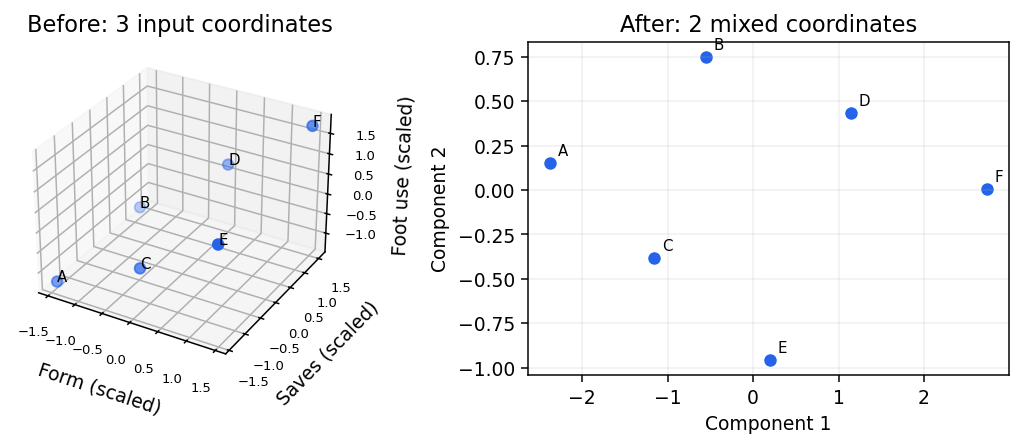

## 5. Methods to compare

| Method | What remains | Trade-off |
|---|---|---|
| No PCA | Selected encoded inputs | Readable; no compression |
| PCA: 95% variation | Enough centered mixtures to retain 95% input variation | Can lose predictive details with little variance |
| TruncatedSVD: 2 components | Two uncentered mixtures | Supports sparse input; two dimensions may lose much detail |
| LDA: 1 direction | One training-label-informed separating direction | Linear assumptions; binary labels allow only one direction |

Compare predictive F1 inside training folds. The later full-training PCA plots illustrate compression; they do not choose the winning representation.

## 6. What we retained from previous notebooks

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("reduce", "passthrough"),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

In [15]:
models = {
    "No PCA": clone(pipeline),
    "PCA: 95% variation": clone(pipeline).set_params(reduce=PCA(n_components=0.95)),
    "SVD: 2 components": clone(pipeline).set_params(reduce=TruncatedSVD(n_components=2, random_state=42)),
    "LDA: 1 direction": clone(pipeline).set_params(reduce=LinearDiscriminantAnalysis(n_components=1)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
0,No PCA,0.880,2.000e-03,0.893,0.960
3,LDA: 1 direction,0.875,9.000e-04,0.888,0.958
1,PCA: 95% variation,0.299,9.100e-03,0.602,0.730
2,SVD: 2 components,0.299,9.100e-03,0.602,0.732


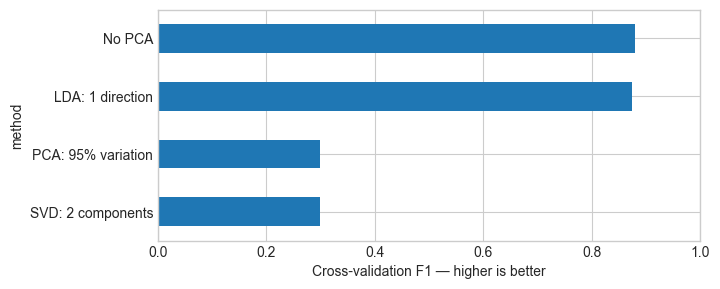

Continue with: No PCA


In [16]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

In [17]:
plot_X, plot_y = X.copy(), y.copy()
plot_X, plot_y = remove_incomplete_rows(plot_X, plot_y)
plot_X = add_features(plot_X)
plot_X = drop_suspected_decoys(plot_X)
encoded = preprocess.fit_transform(plot_X)
encoded_names = preprocess.get_feature_names_out()
plot_selector = clone(pipeline.named_steps["selection"])
encoded = plot_selector.fit_transform(encoded, plot_y)
encoded_names = encoded_names[plot_selector.get_support()]

Before compression: 36 encoded inputs
Two-dimensional picture: 2 mixed coordinates per kick
Components needed for 95% input variation: 2


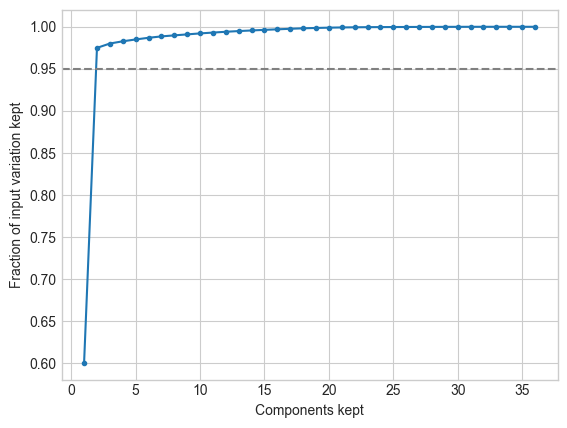

In [18]:
pca = PCA()
points = pca.fit_transform(encoded)
print("Before compression:", encoded.shape[1], "encoded inputs")
print("Two-dimensional picture: 2 mixed coordinates per kick")
components_needed = np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.95) + 1
print("Components needed for 95% input variation:", components_needed)
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker=".")
plt.axhline(0.95, linestyle="--", color="gray")
plt.xlabel("Components kept")
plt.ylabel("Fraction of input variation kept")
plt.show()

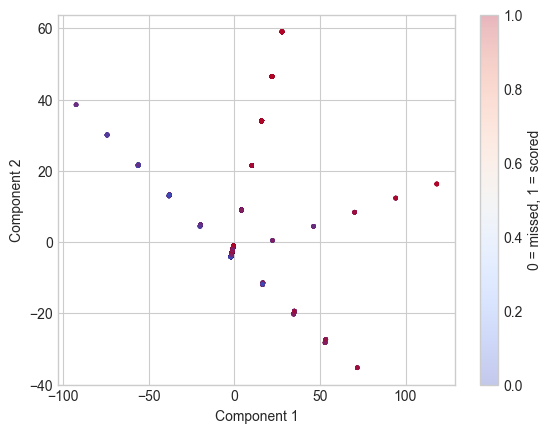

,component 1,component 2
0,-1.772,-3.718
1,-2.003,-4.157
2,-1.585,-3.344
3,-1.695,-3.568
4,-1.687,-3.537


In [19]:
plt.scatter(points[:, 0], points[:, 1], c=plot_y, s=5, alpha=0.3, cmap="coolwarm")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(label="0 = missed, 1 = scored")
plt.show()
display(pd.DataFrame(points[:5, :2], columns=["component 1", "component 2"]))

### Example: what is inside the first component?
The weights below show which encoded inputs contribute most to the mixture; signs give direction.
High retained variation is not the same as retaining goal/miss information.
Robust scaling reduces the influence of typical extremes but does not make every column's variance equal.
Ratios and squared features can still dominate a PCA picture.

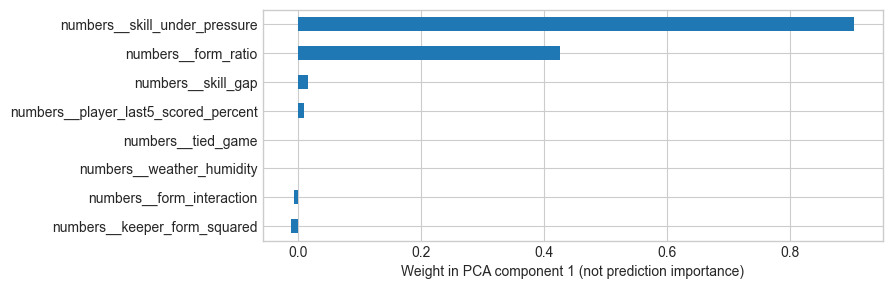

In [20]:
weights = pd.Series(pca.components_[0], index=encoded_names)
largest = weights.abs().nlargest(8).index
weights.loc[largest].sort_values().plot.barh(figsize=(8, 3))
plt.xlabel("Weight in PCA component 1 (not prediction importance)")
plt.show()

**Other alternatives:** kernel PCA captures nonlinear mixtures (more costly); autoencoders learn a compact
representation with a neural network (more settings). t-SNE and UMAP are exploratory maps,
not automatic classification improvements. The PCA picture above illustrates compression; it does not select the winning method.

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Keep the selected inputs, PCA retaining 95% input variation, two-component TruncatedSVD, and one-direction LDA. |
| Which performed best? | No PCA — mean CV F1 0.8800 (rounded saved result). |
| Why did we choose it? | Large-variation mixtures did not improve prediction here; preserving selected original columns is the simpler decision. |
| What are its limitations? | Keeping inputs does not reduce size. PCA variance is not goal/miss information; LDA's linear direction may miss nonlinear structure. |
| What continues to the next notebook? | No PCA: keep the selected encoded inputs. |

## 10. Key takeaways and next step

- Explained variance describes inputs, not classification accuracy.
- Keeping the selected inputs is a valid result when compression lowers F1.

Next: [08 Outlier Handling](08_Outlier_Handling.ipynb).